1. Data

In [ ]:
import yfinance as yf
import pandas as pd

tickers = ["BZ=F", "NG=F"]

data = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-10-30",
    auto_adjust=True,
    progress=False,
)["Close"]

data = data.rename(columns={"BZ=F": "Brent", "NG=F": "NaturalGas"})
data = data.dropna()

print(data.head())
print(data.shape)

Ticker          Brent  NaturalGas
Date                             
2020-01-02  66.250000       2.122
2020-01-03  68.599998       2.130
2020-01-06  68.910004       2.135
2020-01-07  68.269997       2.162
2020-01-08  65.440002       2.141
(1719, 2)


2. Returns

Ticker        Brent   NaturalGas    Portfolio
count   1718.000000  1718.000000  1718.000000
mean       0.000716     0.001396     0.001056
std        0.027888     0.048849     0.029172
min       -0.244036    -0.474799    -0.220514
25%       -0.011753    -0.026168    -0.015612
50%        0.001853     0.001230     0.002161
75%        0.014725     0.026351     0.016395
max        0.210186     0.464812     0.228960


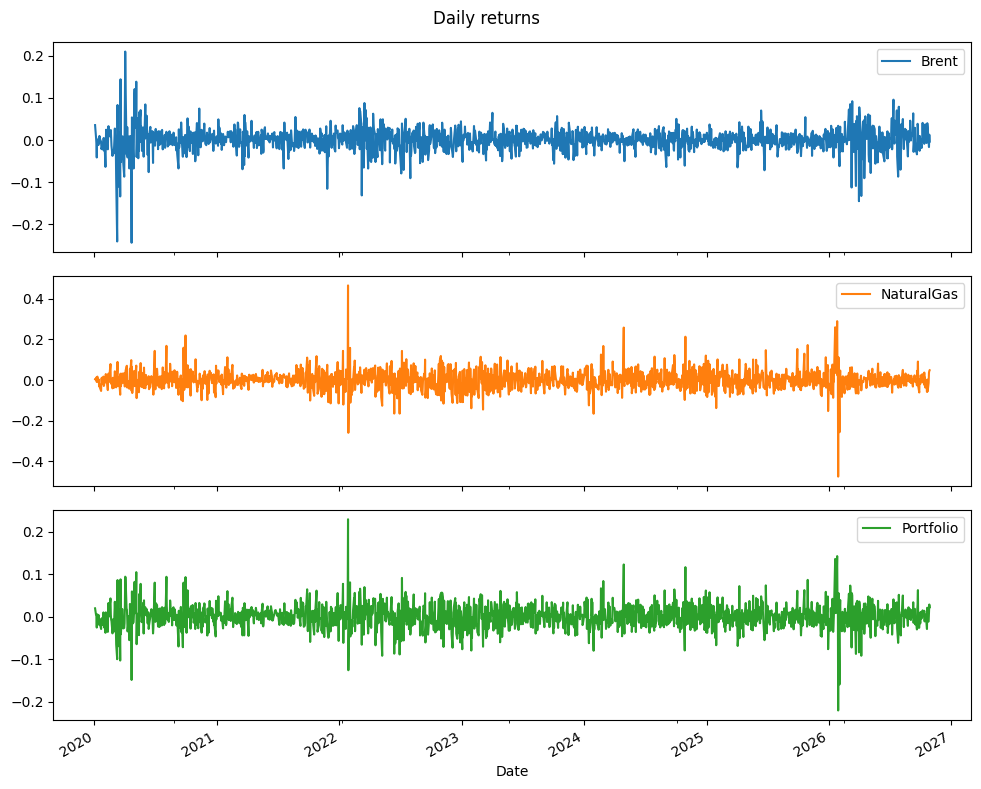

In [ ]:
import matplotlib.pyplot as plt

returns = data.pct_change().dropna()

weights = {"Brent": 0.5, "NaturalGas": 0.5}
returns["Portfolio"] = returns["Brent"] * weights["Brent"] + returns["NaturalGas"] * weights["NaturalGas"]

print(returns.describe())

returns.plot(subplots=True, figsize=(10, 8), title="Daily returns")
plt.tight_layout()
plt.show()

3. Historical VaR

1-day historical VaR 95%: 4.31% (431,489 USD)
1-day historical VaR 99%: 7.28% (728,409 USD)


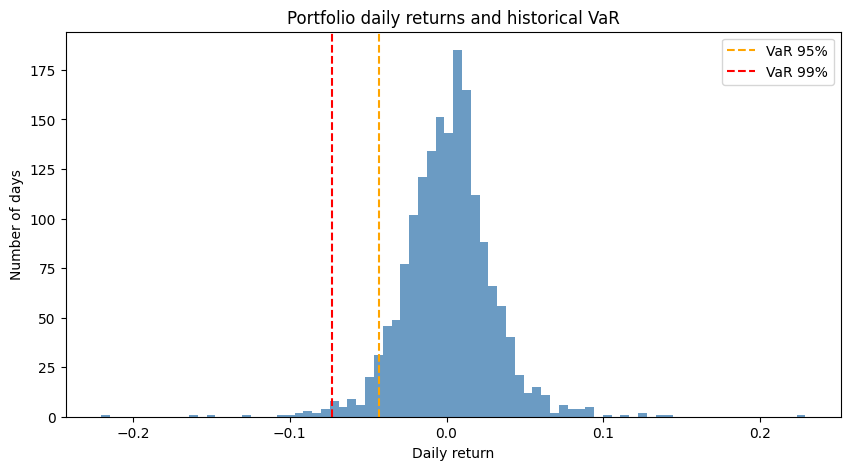

In [ ]:
portfolio_value = 10_000_000

var_95 = -returns["Portfolio"].quantile(0.05)
var_99 = -returns["Portfolio"].quantile(0.01)

print(f"1-day historical VaR 95%: {var_95:.2%} ({var_95 * portfolio_value:,.0f} USD)")
print(f"1-day historical VaR 99%: {var_99:.2%} ({var_99 * portfolio_value:,.0f} USD)")

plt.figure(figsize=(10, 5))
plt.hist(returns["Portfolio"], bins=80, color="steelblue", alpha=0.8)
plt.axvline(-var_95, color="orange", linestyle="--", label="VaR 95%")
plt.axvline(-var_99, color="red", linestyle="--", label="VaR 99%")
plt.title("Portfolio daily returns and historical VaR")
plt.xlabel("Daily return")
plt.ylabel("Number of days")
plt.legend()
plt.show()

4. Parametric VaR

In [ ]:
from scipy.stats import norm

mu = returns["Portfolio"].mean()
sigma = returns["Portfolio"].std()

param_var_95 = -(mu + norm.ppf(0.05) * sigma)
param_var_99 = -(mu + norm.ppf(0.01) * sigma)

results = pd.DataFrame(
    {
        "Historical": [var_95, var_99],
        "Parametric": [param_var_95, param_var_99],
    },
    index=["VaR 95%", "VaR 99%"],
)

print((results * 100).round(2))
print()
print((results * portfolio_value).round(0))

         Historical  Parametric
VaR 95%        4.31        4.69
VaR 99%        7.28        6.68

         Historical  Parametric
VaR 95%    431489.0    469275.0
VaR 99%    728409.0    668081.0


5. Stress tests

                         Portfolio return (%)
Brent -20%                             -10.00
Gas -30%                               -15.00
Brent -20% and Gas -30%                -25.00
Worst day in the data                  -22.05

                         PnL (USD)
Brent -20%              -1000000.0
Gas -30%                -1500000.0
Brent -20% and Gas -30% -2500000.0
Worst day in the data   -2205135.0


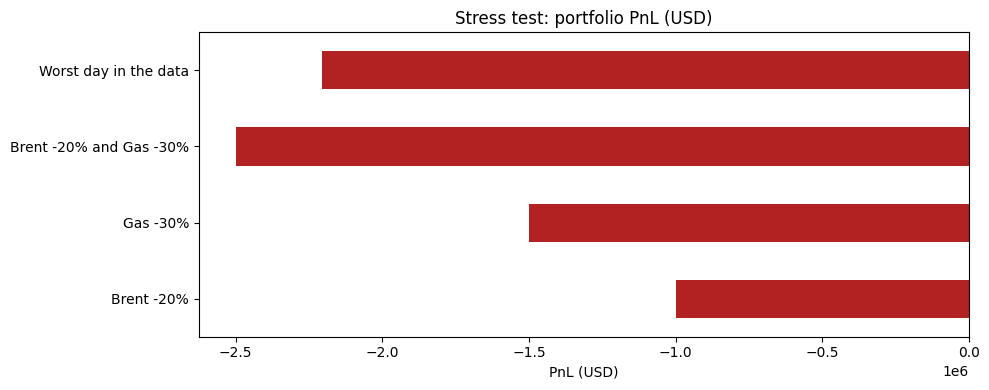

In [ ]:
scenarios = {
    "Brent -20%": {"Brent": -0.20, "NaturalGas": 0.0},
    "Gas -30%": {"Brent": 0.0, "NaturalGas": -0.30},
    "Brent -20% and Gas -30%": {"Brent": -0.20, "NaturalGas": -0.30},
}

stress = {}
for name, shocks in scenarios.items():
    portfolio_shock = sum(weights[asset] * shocks[asset] for asset in weights)
    stress[name] = portfolio_shock

stress["Worst day in the data"] = returns["Portfolio"].min()

stress_table = pd.DataFrame(
    {
        "Portfolio return": pd.Series(stress),
        "PnL (USD)": pd.Series(stress) * portfolio_value,
    }
)

print((stress_table["Portfolio return"] * 100).round(2).to_frame("Portfolio return (%)"))
print()
print(stress_table["PnL (USD)"].round(0).to_frame())

stress_table["PnL (USD)"].plot(kind="barh", color="firebrick", figsize=(10, 4), title="Stress test: portfolio PnL (USD)")
plt.xlabel("PnL (USD)")
plt.tight_layout()
plt.show()

6. PnL attribution

5 worst days (USD):
                Brent  NaturalGas      Total
Date                                        
2026-01-29   168859.0  -2373995.0 -2205135.0
2026-02-02  -310511.0  -1282729.0 -1593239.0
2020-04-21 -1220180.0   -267672.0 -1487851.0
2022-01-28    38617.0  -1297686.0 -1259069.0
2020-03-18  -670031.0   -361481.0 -1031512.0

PnL by year (USD):
          Brent  NaturalGas      Total
Date                                  
2020    13315.0   2042754.0  2056069.0
2021  2295108.0   2715966.0  5011074.0
2022  1031760.0   3357410.0  4389171.0
2023  -292277.0  -1677867.0 -1970144.0
2024    16399.0   3347779.0  3364178.0
2025  -814574.0   1323268.0   508694.0
2026  3904063.0    882695.0  4786758.0



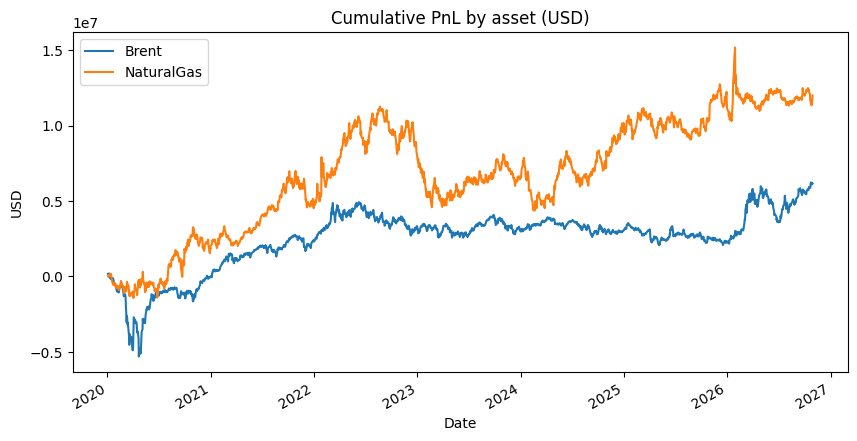

In [ ]:
pnl = pd.DataFrame(
    {
        "Brent": returns["Brent"] * weights["Brent"] * portfolio_value,
        "NaturalGas": returns["NaturalGas"] * weights["NaturalGas"] * portfolio_value,
    }
)
pnl["Total"] = pnl["Brent"] + pnl["NaturalGas"]

print("5 worst days (USD):")
print(pnl.sort_values("Total").head(5).round(0))
print()

print("PnL by year (USD):")
print(pnl.groupby(pnl.index.year).sum().round(0))
print()

pnl[["Brent", "NaturalGas"]].cumsum().plot(figsize=(10, 5), title="Cumulative PnL by asset (USD)")
plt.ylabel("USD")
plt.show()